In [1]:
from os import chdir
from os.path import abspath
thepath = abspath("../base")
chdir(thepath)

In [2]:
# yaml processing file loading. 
import yaml
import numpy as np
import matplotlib.pyplot as plt

from os import makedirs, listdir
from os.path import exists, join, isdir, normpath
from stl import mesh
import iterative_section_minimiser as ism
from utils import find_neighbours_with_knn, return_edge_midpoints, adjust_plane


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


A mapping to the conduits and their number.

In [3]:
with open(f"../notebooks/conduit_map.yaml", "r") as f: 
    conduit_map = yaml.safe_load(f)
    f.close()

A mapping of plotting keyword arguments.

In [4]:
with open(f"../notebooks/plot_kwargs.yaml", "r") as f: 
    p = yaml.safe_load(f)
    f.close()

In [5]:
skeleton_kwargs = p["skeleton_kwargs"]
node_kwargs = p["node_kwargs"]
ct_kwargs = p["ct_kwargs"]
ct1_kwargs = p["ct1_kwargs"]
ct2_kwargs = p["ct2_kwargs"]
mesh_kwargs = p["mesh_kwargs"]
start_kwargs = p["start_kwargs"]
end_kwargs = p["end_kwargs"]

In [6]:
# set up the conduit name and ID. 
ID = 10
CONDUIT_NAME = conduit_map[ID]

In [7]:
## import the mesh data. 
mesh_fp =  f"../data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}.stl"
data = mesh.Mesh.from_file(mesh_fp)

In [8]:
adj_triangles_fp = mesh_fp[:-4] + "_adjacent_triangles.txt"
if not exists(adj_triangles_fp):
    triangle_adjacency_matrix = find_neighbours_with_knn(data)
    np.savetxt(adj_triangles_fp, triangle_adjacency_matrix)
else: 
    triangle_adjacency_matrix = np.loadtxt(adj_triangles_fp)

In [9]:
with open(f"../data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}_processing.yaml", "r") as f: 
    process_p = yaml.safe_load(f)
    f.close()

In [10]:
## find the rings (the largest two clusters of points lying on edges.)
edge_midpoints, labels = return_edge_midpoints(data, triangle_adjacency_matrix)
## fit a plane into the direction of the passage. 
# find the two largest connected components associated with rings. 

# find out the size of the connected components
cc_sizes = [np.sum(labels == c) for c in np.unique(labels)  if c >=0]
# order the indices by decreasing size.
cc_argsort = np.argsort(cc_sizes)[::-1]

# index the rings by their dbscan label and return only the edge midpoint coordinates.
ring1 = edge_midpoints[labels==cc_argsort[0]]
ring2 = edge_midpoints[labels==cc_argsort[1]]

In [11]:
P1, nP1 = adjust_plane(ring1)
P2, nP2 = adjust_plane(ring2)

In [12]:
P1_neighbours = np.logical_and(np.abs((P1 - data.centroids) @ nP1)  < 2 *process_p["iterStepSize"],
                               np.linalg.norm((P1 - data.centroids), axis=1)  < 10 *process_p["iterStepSize"])
P2_neighbours = np.logical_and(np.abs((P2 - data.centroids) @ nP2)  < 2 *process_p["iterStepSize"], 
                               np.linalg.norm((P2 - data.centroids), axis=1)  < 10 *process_p["iterStepSize"])

In [13]:
sign_P1 = np.sign(nP1 @ (np.mean(data.centroids[P1_neighbours], axis =0) - P1))
sign_P2 = np.sign(nP2 @ (np.mean(data.centroids[P2_neighbours], axis =0) - P2))

P1_in = np.mean(ring1, axis =0)+ nP1*sign_P1*process_p["iterStepSize"]*0.01
P2_in = np.mean(ring2, axis =0)+ nP2*sign_P2*process_p["iterStepSize"]*0.01

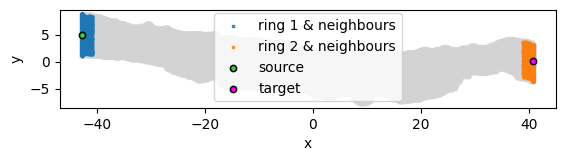

In [14]:
fig, ax = plt.subplots()

ax.scatter(*data.centroids[::50, [0,1]].T, **mesh_kwargs)
ax.scatter(*data.centroids[P1_neighbours][::20, [0,1]].T, s = 1, alpha = 0.15, color = "C0", edgecolors=None)
ax.scatter(*data.centroids[P2_neighbours][::20, [0,1]].T, s = 1, alpha = 0.15, color = "C1", edgecolors=None)

ax.scatter(*ring1[:, [0,1]].T, label = "ring 1 & neighbours", alpha = 0.8, color ="C0", zorder = -1, s = 2, marker = "s")
ax.scatter(*ring2[:, [0,1]].T, label = "ring 2 & neighbours", color = "C1", alpha = 0.8, zorder = -1, s =2, marker="s")

ax.scatter(*P1_in[[0,1]].T, **start_kwargs)
ax.scatter(*P2_in[[0,1]].T, **end_kwargs)
ax.legend()


ax.scatter(*P1[[0,1]].T, **start_kwargs, alpha = 0.15)
ax.scatter(*P2[[0,1]].T, **end_kwargs, alpha = 0.15)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal")
plt.savefig("../temp/figures/supplementary_ring_finding.png", dpi =300)
plt.show()

In [15]:
sign_P1

np.float32(1.0)

In [23]:
L = 90 # guess a max number of steps. 
# if the iterative section minimiser has already been run, then, don't run and
# simply call it up again. 
iterative_ct_fp = join("../temp/", f"{ID}_{CONDUIT_NAME}/iterative/{CONDUIT_NAME}_centreline.txt") 
sections_fp = f"../temp/{ID}_{CONDUIT_NAME}/iterative/sections2d"
sections3d_fp = f"../temp/{ID}_{CONDUIT_NAME}/iterative/sections3d"
iterative_vectors_fp = join("../temp/", f"{ID}_{CONDUIT_NAME}/iterative/{CONDUIT_NAME}_vectors.txt") 

keep_iterative = False

In [24]:
if keep_iterative == True:
    out_iterative = {}
    out_iterative["centreline"] = np.loadtxt(iterative_ct_fp)
    out_iterative["vertices"] = []
    out_iterative["normals"] = np.loadtxt(iterative_vectors_fp)

    for section2d_name in listdir(sections_fp):
        section2d_fp = normpath(join(sections_fp, section2d_name))
        out_iterative["vertices"].append(np.loadtxt(section2d_fp))

else:

    out_iterative = ism.iterative_pathfinder(mesh_data=data,
                                                 P_start=P1_in,
                                                 nP0=nP1.flatten()*sign_P1,
                                                 P_end=P2_in, L=L, ds = process_p["iterStepSize"], eps= 0.05)
    
    
    np.savetxt(iterative_ct_fp, out_iterative["centreline"])
    np.savetxt(iterative_vectors_fp, out_iterative["normals"])

    # save the normals
    #for section2d in sections:
    # save the 2d sections
    if not isdir(sections_fp):
        makedirs(sections_fp)
    for k, section in enumerate(out_iterative["vertices"]):
            np.savetxt(join(sections_fp, f"s2d_{k}.txt"), section)

 83%|████████▎ | 93/112.0 [09:08<01:52,  5.90s/it]


We can extract the iterative centreline from this process. 

In [25]:
iterative_ct = out_iterative["centreline"]

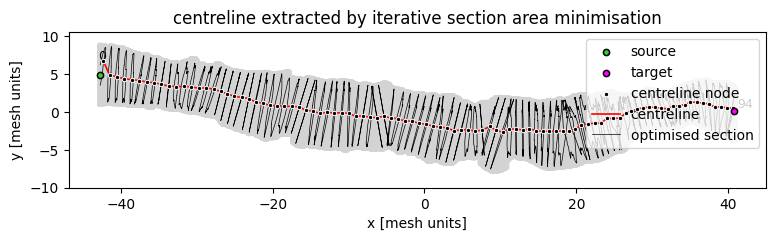

In [26]:
fig, ax = plt.subplots(figsize = (9, 5))
ax.scatter(*P1[[0, 1]],**start_kwargs)
ax.scatter(*P2[[0, 1]], **end_kwargs)

ax.scatter(*data.centroids[::5, [0, 1]].T, **mesh_kwargs)
ax.scatter(*out_iterative["centreline"][:, [0, 1]].T, 
           **node_kwargs, label="centreline node")

ax.plot(*out_iterative["centreline"][:, [0, 1]].T, **ct_kwargs, label="centreline")

for vertex_set in out_iterative["vertices"]:
    ax.plot(*vertex_set[:, [0, 1]].T, color = "k", lw = 0.5)

ax.plot(*out_iterative["vertices"][-1][:, [0, 1]].T, color = "k", lw = 0.5, label="optimised section")
ax.text(*out_iterative["centreline"][0, [0,1]]*1.015, "0", fontsize = "9")
ax.text(*out_iterative["centreline"][-1, [0,1]]*1.015+0.05, f"{len(out_iterative["vertices"])}", fontsize = "9")
## example for the ending criterion- needs to be within epsilon of plane and within d of the barycentre of section.
## if both are good, then stop!
ax.set_ylim(-10, 10.5)
ax.set_title("centreline extracted by iterative section area minimisation")
ax.set_xlabel("x [mesh units]")
ax.set_ylabel("y [mesh units]")
ax.set_aspect("equal")
ax.legend(loc = "upper right")

plt.savefig(f"../temp/{ID}_{CONDUIT_NAME}/iterative/{CONDUIT_NAME}_extremities_iterative_pathfinder.png", dpi = 300)
plt.savefig(f"../temp/{ID}_{CONDUIT_NAME}/iterative/{CONDUIT_NAME}_extremities_iterative_pathfinder.pdf")



We can also plot the number of iterations needed each time to reach the famous eps criterion for stopping. 
As well as the values of W and A which are computed at each step. We define the maximum number of iterations to be 20 and the stopping criterion to be 0.05 (5%).  

In [27]:
logs = out_iterative["logs"]

In [28]:
iteration_progress = []
steps = []
k = 0
j=0
for log in logs:
    
    steps.append(k)
    for iter in log:
        
    
    #print(np.linalg.norm(iter[3]))
        iteration_progress.append((np.linalg.norm(iter[3]), 
                                   iter[4], 
                                   np.linalg.norm(iter[3]) / iter[4], k, j))
        j+=1
    k+=1

In [29]:
iteration_progress = np.array(iteration_progress)

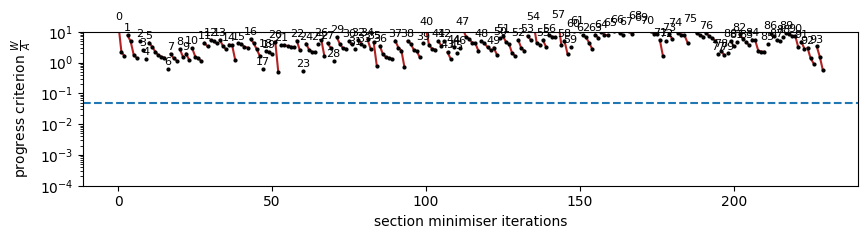

In [30]:
fig, ax= plt.subplots(figsize = (10,2))
for k in np.unique(iteration_progress[:, 3]):
    thebool = iteration_progress[:, 3] == k
    ax.scatter(iteration_progress[thebool, 4],iteration_progress[thebool, 0], color = "k", s = 4)
    ax.semilogy(iteration_progress[thebool, 4],iteration_progress[thebool, 0], color = "firebrick", zorder = -2)
    ax.text(iteration_progress[thebool, 4][0], iteration_progress[thebool, 0][0]*1.15, f"{int(k):d}", va = "bottom", ha="center", fontsize = 8)
ax.set_xlabel("section minimiser iterations")
ax.set_ylabel("progress criterion $\\frac{W}{A}$")
ax.set_ylim(0.0001, 10)
ax.axhline(0.05, color = "C0", ls ="--")

plt.savefig(f"../temp/{ID}_{CONDUIT_NAME}/iterative/{CONDUIT_NAME}_progress_iterative_pathfinder.png", dpi = 300)
plt.savefig(f"../temp/{ID}_{CONDUIT_NAME}/iterative/{CONDUIT_NAME}_progress_iterative_pathfinder.pdf")

